# Copia de consulta — no editar ni usar para entrenar

Original: `notebooks/02_validacion_datos.ipynb` · SHA-256 (UTF-8, saltos LF): `d7feb69ec1246891931deb7b694b94ffe528b69f21441a9c4c075194629a96a4`.

Tipo: **ejecucion_completa**. Fecha de ejecución/consulta: 2026-11-10T02:45:18.004141+00:00. Commit de ejecución: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Entorno de ejecución: `{"Pillow": "12.1.1", "ejecutable_kernel": "python", "kernel": "python3", "matplotlib": "3.10.8", "nbclient": "0.10.4", "numpy": "1.26.4", "pandas": "2.2.2", "python": "3.11.9", "scikit-learn": "1.7.2"}`. Publicación: 2026-11-10T00:35:58-03:00. Commit de referencia del código: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Preparación del insumo: sin celdas omitidas.

Celdas ejecutadas (índices del original): [2, 4, 6, 8, 10, 12, 14]. Familia del test: no aplica.

Una consulta de corridas guardadas muestra resultados reales ya existentes; no reproduce los logs del entrenamiento. Val eligió checkpoints y se usa para reportar. Se quitaron widgets y formatos activos; en test se quitaron todas las imágenes.


<a href="https://colab.research.google.com/github/candeperles/PDI-TP/blob/main/notebooks/02_validacion_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02. Validación del dataset

Auditoría de archivos, etiquetas YOLO, geometría, duplicados y split. **No modifica
imágenes, etiquetas ni la división compartida.** Ejecutar todo.

- **Error:** archivo, anotación o separación que necesita corregirse o justificarse antes de entrenar.
- **Advertencia:** caso para revisar; no se elimina ni transforma automáticamente.
- IDs esperados: `0, 1, 2`. En `solarpanels_hd` son niveles de confianza; ver `docs/criterios_datos.md`.
- Una etiqueta vacía es negativa; una faltante o inválida queda como desconocida.
- Tolerancia de bordes: `1e-6` normalizado por redondeo (0.000256 px en estas imágenes).
- Cajas menores a 3 px en alguna dimensión se señalan para revisión, sin filtrarlas.


In [1]:
# --- Setup: correr siempre primero ---
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/PDI-TP")
    if repo.is_dir():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/candeperles/PDI-TP.git", str(repo)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo / "requirements.txt")], check=True)
else:
    # Funciona al abrir Jupyter desde la raíz o desde notebooks/.
    repo = next((p for p in (Path.cwd(), Path.cwd().parent)
                 if (p / "pdi_tp" / "entorno.py").is_file()), None)
    if repo is None:
        raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde notebooks/.")
os.chdir(repo)
sys.path.insert(0, str(repo))

from pdi_tp import entorno, datos, resultados, split
rutas = entorno.preparar(usar_drive=False)  # no entrena: no monta Drive ni crea carpetas


Dataset:    C:\Users\cande\PDI-TP\data\grupo_5 (900 imágenes)
Resultados: C:\Users\cande\PDI-TP\resultados_locales\resultados (se crea al guardar un modelo)
GPU:        no hay GPU NVIDIA (corriendo en local)


## Ejecutar y exportar

Se revisan todas las imágenes y etiquetas, aunque alguna esté dañada. Los duplicados
se comparan por SHA-256 de los archivos y de los píxeles RGB con sus dimensiones.
Esto detecta copias exactas con distinta compresión o modo de color; **no detecta
imágenes casi iguales**, rotaciones o recortes superpuestos.

La comprobación espacial aplica la heurística ya existente en `pdi_tp/split.py`;
no prueba por sí sola que no haya escenas relacionadas entre grupos distintos.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pdi_tp import validacion

informe = validacion.validar(rutas, clases=(0, 1, 2), minimo_px=3, tolerancia=1e-6)
salida = rutas.analisis / "validacion_datos"
informe.guardar(salida)
print(f"Reporte completo (solo en esta sesión, no se guarda en Drive): {salida}")
display(informe.controles)
display(pd.Series({k: v for k, v in informe.resumen.items() if k != "parametros"}, name="cantidad").to_frame())


Reporte completo (solo en esta sesión, no se guarda en Drive): C:\Users\cande\PDI-TP\resultados_locales\analisis\validacion_datos


,control,estado,errores,advertencias
0,Correspondencia y archivos,ok,0,0
1,Imágenes,ok,0,0
2,Formato y clases YOLO,ok,0,0
3,Geometría de cajas,error,1,0
4,Cajas pequeñas,revisar,0,37
5,Duplicados exactos,ok,0,0
6,Integridad del split,ok,0,0
7,Separación espacial,ok,0,0


,cantidad
imagenes,900
etiquetas,900
imagenes_legibles,900
etiquetas_validas,899
imagenes_con_paneles,760
imagenes_sin_paneles,139
imagenes_etiqueta_desconocida,1
cajas_numericas_finitas,2669
cajas_validas,2668
cajas_pequenas,37


## Imágenes, etiquetas y clases

El modo paleta `P` se registra, pero no es un error: el lector compartido convierte
las imágenes a RGB. Las cajas de la tabla siguiente son filas de cinco valores
numéricos finitos; los problemas de lectura están detallados en las incidencias.


In [3]:
display(informe.imagenes.groupby(["ancho", "alto", "modo"], dropna=False).size().rename("imagenes").to_frame())
display(informe.cajas.groupby(["clase", "valida"], dropna=False).size().rename("cajas").to_frame())
display(informe.imagenes.groupby(["split", "fuente"], dropna=False).agg(
    imagenes=("archivo", "size"), etiquetas_validas=("etiqueta_valida", "sum")))


imagenes
ancho alto modo          
256   256  P           54
           RGB        846

cajas
clase valida       
0.0   False       1
      True     2651
1.0   True        8
2.0   True        9

imagenes  etiquetas_validas
split fuente                                     
train PV01                 188                188
      geo                   62                 62
      kingston              47                 47
      kingston2             40                 40
      solarpanels_hd       401                400
val   PV01                  40                 40
      geo                   11                 11
      kingston               7                  7
      kingston2              5                  5
      solarpanels_hd        99                 99

## Tabla de incidencias

Cada fila indica un problema y, si corresponde, la línea de la etiqueta original.
Una caja puede tener más de una incidencia; el total de incidencias no es el total
de cajas afectadas. Los CSV contienen todos los registros, sin el límite de esta vista.


In [4]:
if informe.incidencias.empty:
    print("No se encontraron incidencias.")
else:
    display(informe.incidencias.groupby(["nivel", "control"]).agg(
        incidencias=("archivo", "size"), archivos=("archivo", "nunique")))
    with pd.option_context("display.max_colwidth", 140):
        display(informe.incidencias.head(50))


,,incidencias,archivos
nivel,control,,
advertencia,caja_pequena,37,32
error,dimension_caja_no_positiva,1,1


,nivel,control,archivo,linea,detalle
0,advertencia,caja_pequena,PV01_325159_1203813.png,5,1.0000 × 6.0000 px; umbral de revisión: 3 px.
1,advertencia,caja_pequena,PV01_325190_1204153.png,3,2.0000 × 5.0000 px; umbral de revisión: 3 px.
2,advertencia,caja_pequena,PV01_325199_1204178.png,1,6.0000 × 2.0000 px; umbral de revisión: 3 px.
3,advertencia,caja_pequena,PV01_325206_1204153.png,12,2.0000 × 1.0000 px; umbral de revisión: 3 px.
4,advertencia,caja_pequena,PV01_325206_1204178.png,3,1.0000 × 1.0000 px; umbral de revisión: 3 px.
5,advertencia,caja_pequena,PV01_325208_1204153.png,1,2.0000 × 1.0000 px; umbral de revisión: 3 px.
6,advertencia,caja_pequena,PV01_325208_1204161.png,6,1.0000 × 3.0000 px; umbral de revisión: 3 px.
7,advertencia,caja_pequena,PV01_325208_1204172.png,6,1.0000 × 4.0000 px; umbral de revisión: 3 px.
8,advertencia,caja_pequena,PV01_325213_1204208.png,1,2.0000 × 5.0000 px; umbral de revisión: 3 px.
9,advertencia,caja_pequena,PV01_325215_1204200.png,2,3.0000 × 2.0000 px; umbral de revisión: 3 px.


## Ejemplos de errores y cajas pequeñas

La tabla da el nombre completo. En los gráficos `L` es la línea de la etiqueta y `C`
el ID de clase. Las cajas se dibujan sin corregir ni recortar sus coordenadas.


,archivo,split,etiqueta_valida
451,solarpanels_hd_1__x0_13014_y0_24247_dxdy_832_1...,train,False


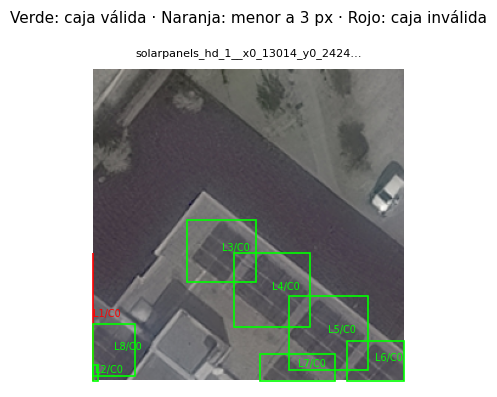

,archivo,linea,w_px,h_px,valida
655,PV01_325206_1204178.png,3,1.000000,1.000000,True
948,PV01_325217_1204205.png,1,1.000000,1.000000,True
913,PV01_325215_1204202.png,1,1.000000,2.000000,True
1422,PV01_325359_1205353.png,2,1.000000,2.000000,True
725,PV01_325208_1204161.png,6,1.000000,3.000000,True
755,PV01_325208_1204172.png,6,1.000000,4.000000,True
218,PV01_325159_1203813.png,5,1.000000,6.000000,True
2003,solarpanels_hd_1__x0_13115_y0_17914_dxdy_832_2...,1,1.230848,4.923136,True
2565,solarpanels_hd_3__x0_13356_y0_22432_dxdy_832_0...,2,1.230848,4.923136,True
2161,solarpanels_hd_1__x0_16982_y0_16830_dxdy_832_3...,1,1.230848,32.000000,True


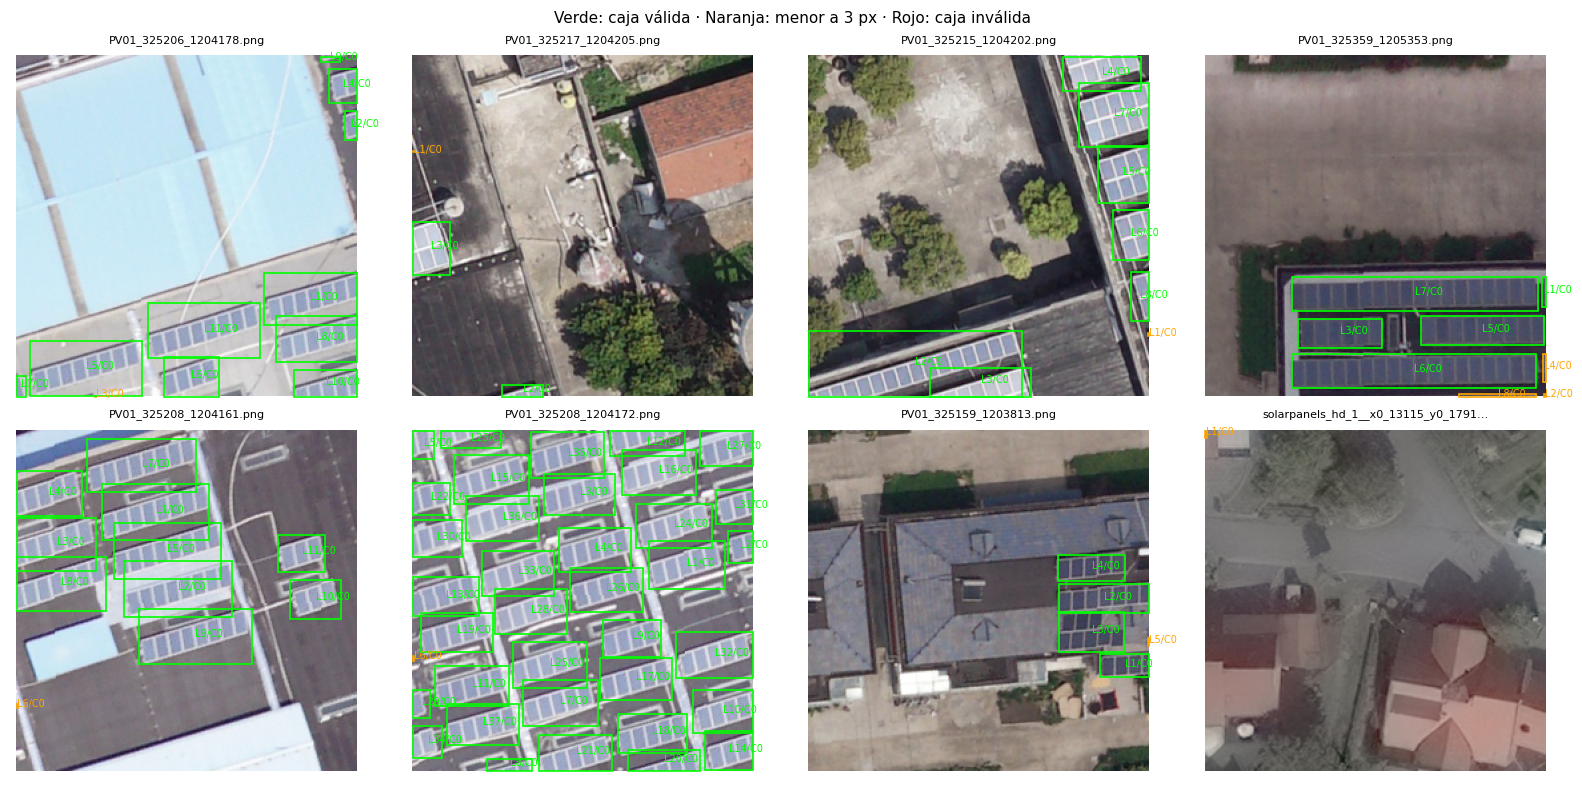

In [5]:
candidatos = informe.incidencias.loc[
    (informe.incidencias["nivel"] == "error") & informe.incidencias["archivo"].isin(informe.imagenes["archivo"]),
    "archivo"].drop_duplicates().head(8).tolist()
display(informe.imagenes.loc[informe.imagenes["archivo"].isin(candidatos), ["archivo", "split", "etiqueta_valida"]])
fig = validacion.dibujar_ejemplos(informe, rutas, candidatos)
if fig is not None:
    fig.savefig(salida / "ejemplos_errores.png", dpi=120, bbox_inches="tight")
    display(fig)
    plt.close(fig)

pequenas = informe.cajas.loc[informe.cajas["pequena"]].sort_values(["w_px", "h_px"])
display(pequenas[["archivo", "linea", "w_px", "h_px", "valida"]].head(12))
fig = validacion.dibujar_ejemplos(informe, rutas, pequenas["archivo"], maximo=8)
if fig is not None:
    fig.savefig(salida / "ejemplos_cajas_pequenas.png", dpi=120, bbox_inches="tight")
    display(fig)
    plt.close(fig)


## Duplicados exactos

Un mismo grupo puede aparecer en la comparación por bytes y por píxeles: no sumar
ambos como si fueran grupos diferentes. Un duplicado que cruza train/val se marca
como error. Si tiene anotaciones distintas, también se registra una advertencia.


In [6]:
display(informe.duplicados)
if not informe.duplicados.empty:
    nombres = [n for grupo in informe.duplicados.loc[informe.duplicados["tipo"] == "pixeles_rgb", "archivos"]
               for n in grupo.split(" | ")]
    fig = validacion.dibujar_ejemplos(informe, rutas, nombres, maximo=8)
    if fig is not None:
        fig.savefig(salida / "ejemplos_duplicados.png", dpi=120, bbox_inches="tight")
        display(fig)
        plt.close(fig)


,tipo,hash,cantidad,archivos,entre_splits


## Clases minoritarias para revisión visual

Esta galería ayuda a revisar los IDs 1 y 2. Su significado en `solarpanels_hd` se cotejó con la fuente original: confianza moderada y baja. La fusión en una clase "panel" para el futuro derivado está documentada en `docs/criterios_datos.md`.


,archivo,linea,clase,w_px,h_px,valida
2129,solarpanels_hd_1__x0_16473_y0_15637_dxdy_832_0...,1,2.0,48.000000,57.846272,True
2155,solarpanels_hd_1__x0_16815_y0_17593_dxdy_832_1...,1,2.0,77.538560,83.692288,True
2181,solarpanels_hd_1__x0_18698_y0_21896_dxdy_832_3...,1,2.0,57.846272,119.384576,True
2184,solarpanels_hd_1__x0_18744_y0_22105_dxdy_832_2...,1,2.0,57.846272,119.384576,True
2264,solarpanels_hd_1__x0_4548_y0_16371_dxdy_832_0_...,1,2.0,50.461440,39.384576,True
2274,solarpanels_hd_1__x0_4791_y0_16369_dxdy_832_0_...,1,2.0,50.461440,39.384576,True
2394,solarpanels_hd_2__x0_10085_y0_11459_dxdy_832_0...,1,2.0,39.384576,40.615424,True
2400,solarpanels_hd_2__x0_10179_y0_13259_dxdy_832_3...,1,1.0,41.846272,45.538560,True
2422,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832_2_...,1,1.0,123.076864,99.692288,True
2424,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832_2_...,3,1.0,119.384576,92.307712,True


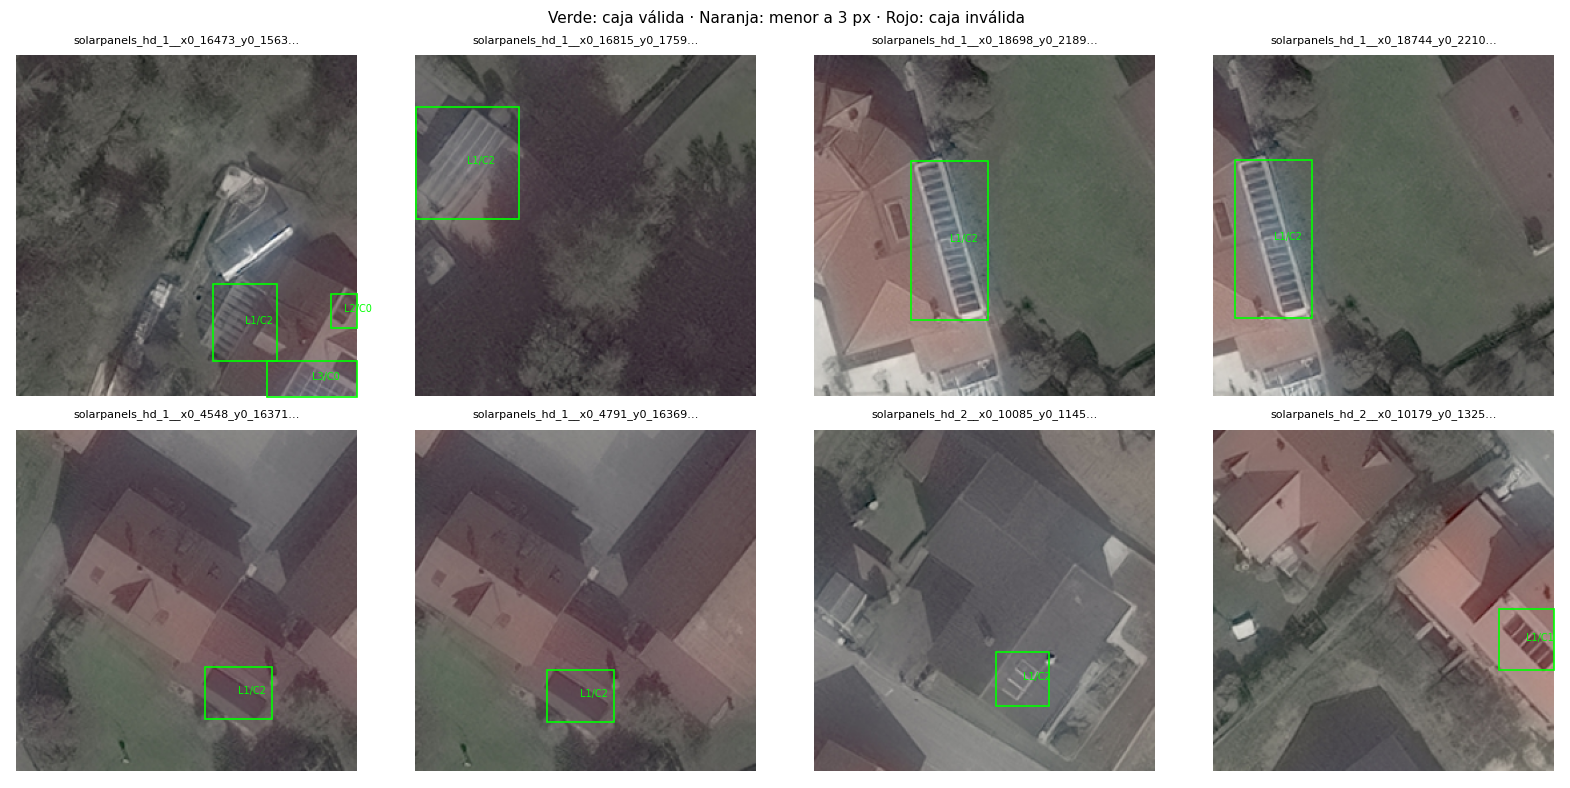

In [7]:
raras = informe.cajas.loc[informe.cajas["clase"].isin([1, 2])]
display(raras[["archivo", "linea", "clase", "w_px", "h_px", "valida"]])
fig = validacion.dibujar_ejemplos(informe, rutas, raras["archivo"], maximo=8)
if fig is not None:
    fig.savefig(salida / "ejemplos_clases_minoritarias.png", dpi=120, bbox_inches="tight")
    display(fig)
    plt.close(fig)


## Qué decidir después

1. Revisar los errores y sus líneas antes de preparar datos de entrenamiento.
2. Consultar la definición de clases y decisiones en `docs/criterios_datos.md`.
3. Conservar cajas pequeñas y originales; excluir la caja nula solo al preparar el derivado.
4. Si se requieren cambios del split, decidirlos como equipo y versionar una nueva división.

No aplicar correcciones silenciosas. La validación estructural no comprueba por sí
sola que todas las anotaciones sean semánticamente correctas o estén completas.
